# Visualisasi — Presentasi (bercerita dengan grafik + ekspor otomatis ke PowerPoint)
**Kapan dipakai:** di akhir lomba, mengubah temuan menjadi slide yang langsung dimengerti juri.

**Isi:** KPI tile, grafik dengan judul = kesimpulan, sorot satu warna sisanya abu, anotasi
angka di grafik, sebelum-sesudah, ranking dengan sorotan, lalu **ekspor PNG ke satu file
.pptx** (satu gambar per slide, judul slide dari nama file).

**Data demo:** Titanic (kisah: siapa yang selamat).

**Lima aturan grafik presentasi**
1. Judul = kesimpulan ("Kelas 1 dua kali lebih mungkin selamat"), bukan nama grafik.
2. Satu grafik, satu pesan. Pesan kedua = slide berikutnya.
3. Sorot satu warna (biru) untuk yang penting, sisanya abu.
4. Tulis angka langsung di grafik; hapus gridline, legenda, dan sumbu yang tidak perlu.
5. Font besar (>= 14 pt), kontras tinggi, jangan andalkan merah-hijau saja.

In [1]:
import glob
import os

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from lightgbm import LGBMClassifier
from matplotlib.patches import FancyBboxPatch
from PIL import Image
from pptx import Presentation
from pptx.util import Inches, Pt
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/tabular/classification"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/titanic_train.csv"

TARGET = "survived"
FEATURE_COLS = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
CATEGORY_COLS = ["sex", "embarked"]
IMAGE_FOLDER = "."               # folder PNG yang diekspor ke .pptx ("." = folder notebook)
IMAGE_PATTERN = "pres_*.png"     # ganti "*.png" untuk memasukkan semua gambar di folder itu
SEED = 42

## Gaya grafik (sama di semua notebook visualisasi)
Font besar supaya terbaca di slide, palet tetap, garis tepi atas/kanan dimatikan.

In [3]:
PALETTE = ["#2E6FB7", "#F28E2B", "#3BA272", "#D1495B", "#7B5EA7", "#9AA0A6"]
BLUE, ORANGE, GREEN, RED, PURPLE, GREY = PALETTE
plt.rcParams.update({
    "figure.figsize": (8, 5), "figure.dpi": 100, "savefig.dpi": 200,
    "font.size": 14, "axes.titlesize": 18, "axes.titleweight": "bold", "axes.labelsize": 14,
    "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
})
sns.set_palette(PALETTE)

## Baca data dan hitung angka cerita

In [4]:
titanic = pd.read_csv(TRAIN_CSV)
titanic["class_name"] = titanic["pclass"].map({1: "Kelas 1", 2: "Kelas 2", 3: "Kelas 3"})
percent_total = titanic[TARGET].mean() * 100
percent_by_class = titanic.groupby("class_name")[TARGET].mean() * 100
percent_by_sex = titanic.groupby("sex")[TARGET].mean() * 100
print(titanic.shape)
print(percent_by_class.round(0))
print(percent_by_sex.round(0))

(712, 17)
class_name
Kelas 1    65.0
Kelas 2    45.0
Kelas 3    24.0
Name: survived, dtype: float64
sex
female    74.0
male      19.0
Name: survived, dtype: float64


## 1. KPI tile (angka besar)
**Kapan dipakai:** slide pembuka/ringkasan; 3-4 angka yang harus diingat juri.
**Cara baca:** angka besar = hasil utama, teks kecil = artinya. Maksimal 4 tile.

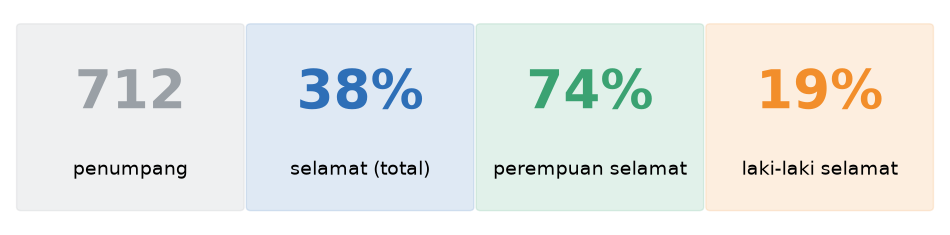

In [5]:
kpi_values = [f"{len(titanic):,}", f"{percent_total:.0f}%",
              f"{percent_by_sex['female']:.0f}%", f"{percent_by_sex['male']:.0f}%"]
kpi_labels = ["penumpang", "selamat (total)", "perempuan selamat", "laki-laki selamat"]
kpi_colors = [GREY, BLUE, GREEN, ORANGE]
fig, ax = plt.subplots(figsize=(12, 2.8))
ax.axis("off")
ax.set_xlim(-0.05, 4.2)
ax.set_ylim(-0.1, 1.1)
for i in range(len(kpi_values)):
    left = i * 1.05
    tile = FancyBboxPatch((left, 0), 1, 1, boxstyle="round,pad=0.02", color=kpi_colors[i],
                          alpha=0.15)
    ax.add_patch(tile)
    ax.text(left + 0.5, 0.55, kpi_values[i], ha="center", fontsize=38, fontweight="bold",
            color=kpi_colors[i])
    ax.text(left + 0.5, 0.18, kpi_labels[i], ha="center", fontsize=14)
plt.savefig("pres_01_kpi_tile.png", dpi=200, bbox_inches="tight")
plt.show()

## 2. Judul = kesimpulan + sorot satu warna
**Kapan dipakai:** membandingkan kategori; satu kategori adalah bintangnya.
**Cara baca:** bar biru = fokus cerita, abu = pembanding. Angka di atas bar, sumbu y dihapus.

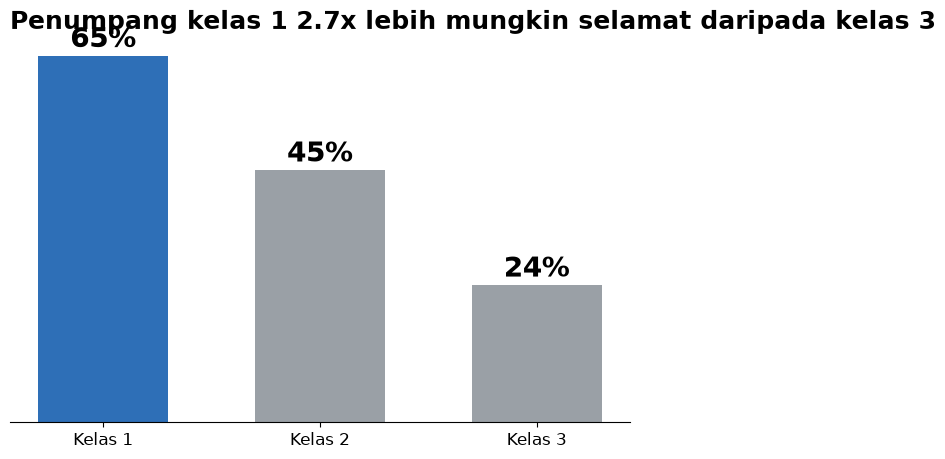

In [6]:
ratio = percent_by_class["Kelas 1"] / percent_by_class["Kelas 3"]
bar_colors = []
for name in percent_by_class.index:
    if name == "Kelas 1":
        bar_colors.append(BLUE)   # sorot satu kategori
    else:
        bar_colors.append(GREY)
plt.bar(percent_by_class.index, percent_by_class.values, color=bar_colors, width=0.6)
for i, value in enumerate(percent_by_class):
    plt.text(i, value + 1.5, f"{value:.0f}%", ha="center", fontsize=20, fontweight="bold")
plt.title(f"Penumpang kelas 1 {ratio:.1f}x lebih mungkin selamat daripada kelas 3", loc="left")
plt.yticks([])
plt.grid(False)
plt.gca().spines["left"].set_visible(False)
# Nama kategori panjang? pakai bar horizontal: plt.barh(percent_by_class.index, ...)
plt.savefig("pres_02_sorot_kelas.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Anotasi angka dan panah pada garis
**Kapan dipakai:** tren/pola yang puncaknya adalah pesan utama.
**Cara baca:** garis abu = pola umum, titik merah + panah = temuan yang harus diperhatikan.

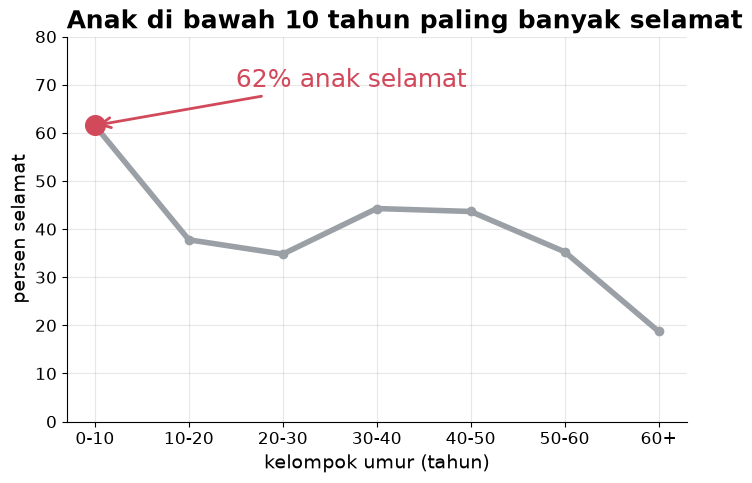

In [7]:
age_edges = [0, 10, 20, 30, 40, 50, 60, 80]
age_names = ["0-10", "10-20", "20-30", "30-40", "40-50", "50-60", "60+"]
age_group = pd.cut(titanic["age"], age_edges, labels=age_names)
percent_by_age = titanic.groupby(age_group, observed=True)[TARGET].mean() * 100
child_percent = percent_by_age.iloc[0]
plt.plot(age_names, percent_by_age.values, color=GREY, linewidth=4, marker="o")
plt.scatter(0, child_percent, color=RED, s=200, zorder=3)
plt.annotate(f"{child_percent:.0f}% anak selamat", (0, child_percent),
             xytext=(1.5, child_percent + 8), fontsize=18, color=RED,
             arrowprops={"arrowstyle": "->", "color": RED, "linewidth": 2})
plt.title("Anak di bawah 10 tahun paling banyak selamat", loc="left")
plt.xlabel("kelompok umur (tahun)")
plt.ylabel("persen selamat")
plt.ylim(0, 80)
plt.savefig("pres_03_anotasi_umur.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Sebelum-sesudah
**Kapan dipakai:** menunjukkan manfaat model/perbaikan dibanding cara lama.
**Cara baca:** abu = sebelum (baseline), biru = sesudah (model); angka selisih ditulis besar.
Model dilatih cepat di sel ini hanya untuk bahan grafik.

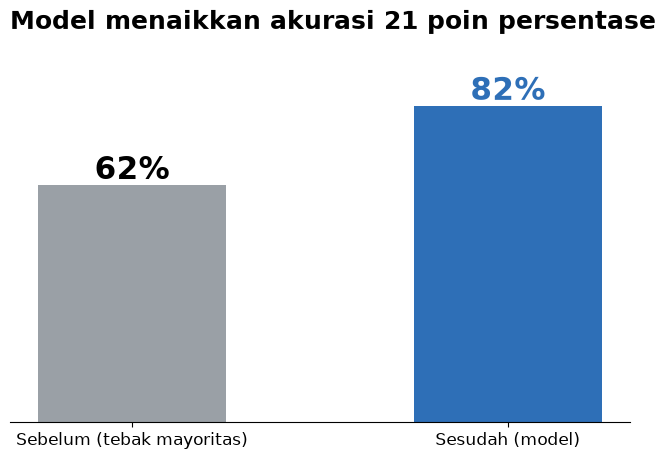

In [8]:
X = titanic[FEATURE_COLS].copy()
for column in CATEGORY_COLS:
    X[column] = X[column].astype("category")
y = titanic[TARGET]
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.3, stratify=y,
                                                  random_state=SEED)
model = LGBMClassifier(n_estimators=150, learning_rate=0.05, random_state=SEED, verbose=-1)
# model = CatBoostClassifier(verbose=0, cat_features=CATEGORY_COLS)   # kategori ditangani sendiri
model.fit(X_train, y_train)
before = y_val.value_counts(normalize=True).max() * 100   # baseline: tebak kelas terbanyak
after = accuracy_score(y_val, model.predict(X_val)) * 100
plt.bar(["Sebelum (tebak mayoritas)", "Sesudah (model)"], [before, after], color=[GREY, BLUE],
        width=0.5)
plt.text(0, before + 1.5, f"{before:.0f}%", ha="center", fontsize=22, fontweight="bold")
plt.text(1, after + 1.5, f"{after:.0f}%", ha="center", fontsize=22, fontweight="bold",
         color=BLUE)
plt.title(f"Model menaikkan akurasi {after - before:.0f} poin persentase", loc="left")
plt.ylim(0, 100)
plt.yticks([])
plt.grid(False)
plt.gca().spines["left"].set_visible(False)
plt.savefig("pres_04_sebelum_sesudah.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Ranking dengan satu sorotan
**Kapan dipakai:** menyebut faktor terpenting (importance, skor, penjualan) di slide.
**Cara baca:** hanya bar teratas yang berwarna biru; cukup 5-8 bar terurut.

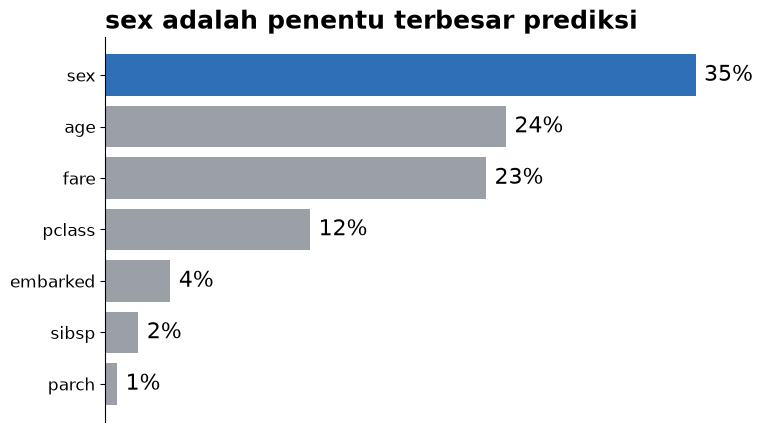

In [9]:
gain = model.booster_.feature_importance("gain")
importance = pd.Series(gain, index=FEATURE_COLS)
importance = importance / importance.sum() * 100     # jadi persen
importance = importance.sort_values()
bar_colors = []
for name in importance.index:
    if name == importance.index[-1]:
        bar_colors.append(BLUE)    # hanya yang teratas disorot
    else:
        bar_colors.append(GREY)
plt.barh(importance.index, importance.values, color=bar_colors)
for i, value in enumerate(importance):
    plt.text(value + 0.5, i, f"{value:.0f}%", va="center", fontsize=16)
plt.title(f"{importance.index[-1]} adalah penentu terbesar prediksi", loc="left")
plt.xticks([])
plt.grid(False)
plt.gca().spines["bottom"].set_visible(False)
plt.savefig("pres_05_ranking_sorot.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Ekspor PNG ke satu file .pptx
**Kapan dipakai:** 30 menit terakhir sebelum presentasi; slide kasar langsung jadi, lalu tinggal
merapikan di PowerPoint (tambah narasi, urutan, logo).
**Cara baca:** satu gambar per slide (urut nama file), judul slide = nama file. Awali nama
gambar dengan nomor (01_, 02_) untuk mengatur urutan. Untuk mengambil gambar notebook lain,
ubah `IMAGE_FOLDER` / `IMAGE_PATTERN` di Konfigurasi.

In [10]:
deck = Presentation()
deck.slide_width = Inches(13.333)
deck.slide_height = Inches(7.5)
blank_layout = deck.slide_layouts[6]
for file in sorted(glob.glob(f"{IMAGE_FOLDER}/{IMAGE_PATTERN}")):
    slide = deck.slides.add_slide(blank_layout)
    file_name = os.path.splitext(os.path.basename(file))[0]   # "pres_01_kpi_tile"
    title = slide.shapes.add_textbox(Inches(0.5), Inches(0.25), Inches(12.3), Inches(0.8))
    title.text_frame.text = file_name.replace("_", " ")
    title.text_frame.paragraphs[0].font.size = Pt(28)
    title.text_frame.paragraphs[0].font.bold = True
    width, height = Image.open(file).size
    scale = min(12.3 / width, 5.9 / height)      # muat di area gambar, rasio tetap
    left = (13.333 - width * scale) / 2
    slide.shapes.add_picture(file, Inches(left), Inches(1.3), Inches(width * scale))
deck.save("presentasi.pptx")
print("slide dibuat:", len(deck.slides), "->", "presentasi.pptx")

slide dibuat: 5 -> presentasi.pptx
